In [246]:
import os
os.environ['KERAS_BACKEND'] = 'jax'
os.environ["PYTHONHASHSEED"] = "0"
import keras
keras.utils.set_random_seed(42) 
import tensorflow as tf

import pickle
import time
import bayesflow as bf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from constants import SHAPE_PRIOR_RANGES, FLASH_PAIRS, CUE, HAS_DEADLINE, BASE_PARAMS, MODEL_NAMES
from functions.prior import prior
from functions.likelihood import likelihood
from functions.resimulate_from_posterior import resimulate_from_posterior

In [247]:
simulator = bf.make_simulator([prior, likelihood])

sim_draws = simulator.sample(50)

In [248]:
par_keys = [
    "a_base",
    "v_scale",
    "t0",
    
]
par_names = [r"$a_\text{base}$", r"$v_\text{scale}$", r"$t_0$",]

In [249]:
# f = bf.diagnostics.plots.pairs_samples(
#     samples=sim_draws,
#     variable_keys=par_keys,
#     variable_names=par_names
# )

In [250]:
# 4 Parameter: v_scale, t0, a, lam
num_params = 4

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [251]:
["v_scale", "t0", "a_base",SHAPE_PRIOR_RANGES[MODEL_NAMES[0]][0]]

['v_scale', 't0', 'a_base', 'k_sig']

In [252]:
@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # if required keys are not present: return data as is
    # handle cases where data is already processed or in inverse mode
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # stack rt, choice, and coherence along a new axis to create 2D array
    # Each row is one trial, and columns are features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # new dictionary from input data
    # and adding 'summary_variables'
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    .concatenate(["v_scale", "t0", "a_base",SHAPE_PRIOR_RANGES[MODEL_NAMES[0]][0], SHAPE_PRIOR_RANGES[MODEL_NAMES[0]][1]], into="inference_variables")
    .add_transform(stack_trials_for_deepset)
    .keep(["inference_variables", "summary_variables"])
)

In [253]:
 # coherence is present in the summary variables, so its going in the network.
sample = simulator.sample(batch_shape=(4,))
adapted = adapter(sample)
sv = adapted["summary_variables"]
print(sv.shape)                     
print(np.unique(sv[0, :, 2]))       

(4, 360, 3)
[0.1 0.2 0.3 0.4 0.5 0.6]


In [254]:

CHECKPOINT_DIR = os.path.join("models", "checkpoints", "ddm_sbi_run")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("./models/networks", exist_ok=True) 

print(CHECKPOINT_DIR)

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name="ddm_workflow_",
)


Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("models\checkpoints\ddm_sbi_run/ddm_workflow_.keras")


models\checkpoints\ddm_sbi_run


In [255]:
print(workflow.adapter)

Adapter([0: ToArray -> 1: ConvertDType -> 2: Concatenate(['v_scale', 't0', 'a_base', 'k_sig', 't_mid'] -> 'inference_variables') -> 3: <function stack_trials_for_deepset at 0x00000147016E98A0> -> 4: Keep(['inference_variables', 'summary_variables'])])


In [256]:
## TRAINING THE MODEL
# commented out because of runtime

EPOCHS, BATCH_SIZE, NUM_BATCHES = 10, 8, 5

history = workflow.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE, num_batches_per_epoch=NUM_BATCHES)

history_path = f"./models/networks/bayesflow_history_epoch_{EPOCHS}_{MODEL_NAMES[0]}.pkl"
tmp_path = history_path + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(history, f)
os.replace(tmp_path, history_path)

print(f"History saved successfully to {history_path}!")
print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")

print("!!! CHANGE name of ddm_workflow to incorporate model name")


INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - loss: 6.6554
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - loss: 6.2686
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - loss: 6.4925
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - loss: 6.7560
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - loss: 6.6862
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - loss: 6.4445
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - loss: 6.1449
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - loss: 6.4345
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - loss: 5.8802
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - loss: 6.2501


INFO:bayesflow:Training completed in 1.80 minutes.
INFO:bayesflow:Training is now finished.
You can find the trained approximator at 'models\checkpoints\ddm_sbi_run/ddm_workflow_.keras'.
To load it, use approximator = keras.saving.load_model("models\checkpoints\ddm_sbi_run/ddm_workflow_.keras").


History saved successfully to ./models/networks/bayesflow_history_epoch_10_sigmoid.pkl!
Model weights were checkpointed automatically to models\checkpoints\ddm_sbi_run/
!!! CHANGE name of ddm_workflow to incorporate model name


In [257]:
print(workflow.adapter)

Adapter([0: ToArray -> 1: ConvertDType -> 2: Concatenate(['v_scale', 't0', 'a_base', 'k_sig', 't_mid'] -> 'inference_variables') -> 3: <function stack_trials_for_deepset at 0x00000147016E98A0> -> 4: Keep(['inference_variables', 'summary_variables'])])


In [258]:
# load model with exponential decision boundary
history_path = f"./models/networks/bayesflow_history_epoch_{EPOCHS}_{MODEL_NAMES[0]}.pkl"
if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )


approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, f"ddm_workflow_{MODEL_NAMES[0]}.keras"))


## **Diagnostics**

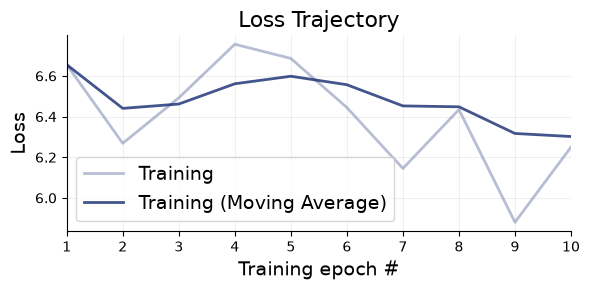

In [259]:
# Convergence
f  = bf.diagnostics.loss(history, figsize=(6,3))
f.savefig(f"images/diagnostics/loss_{MODEL_NAMES[0]}.pdf")

In [260]:
# SB calibration
#workflow.approximator = approximator

# recovery rates

num_samples = 100
test_sims = workflow.simulate(100)
test_sims_params = {k: v for k, v in test_sims.items() if k in par_keys}
test_sims_data = {k: v for k, v in test_sims.items() if k not in par_keys}

samples = workflow.sample(conditions=test_sims_data, num_samples=num_samples)



Sampling: 100%|██████████| 1/1 [00:00<00:00,  3.84batch/s]
INFO:bayesflow:Sampling completed in 1.49 seconds.


In [261]:
# settings for plots
label_map = {
    "v_scale": r"$v_{scale}$",
    "t0": r"$t_0$",
    "a_base": r"$a_{base}$",
    "lam": r"$\lambda$",
    "t_mid": r"$t_{\text{mid}}$",
    "k_sig": r"$k_\text{sig}$"
}

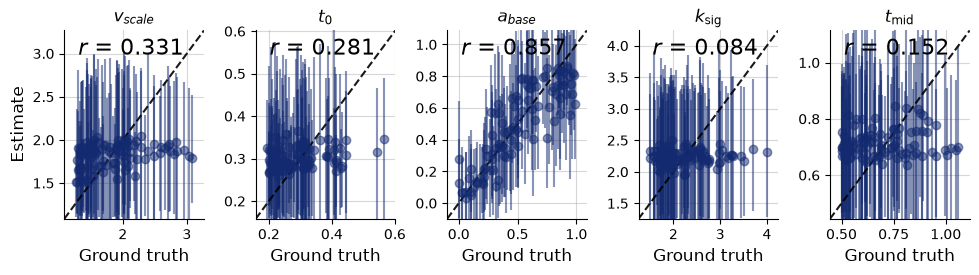

In [262]:
f2 = bf.diagnostics.recovery(samples, test_sims, figsize = (10,3))

for ax in f2.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

f2.savefig(f"images/diagnostics/recovery_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")

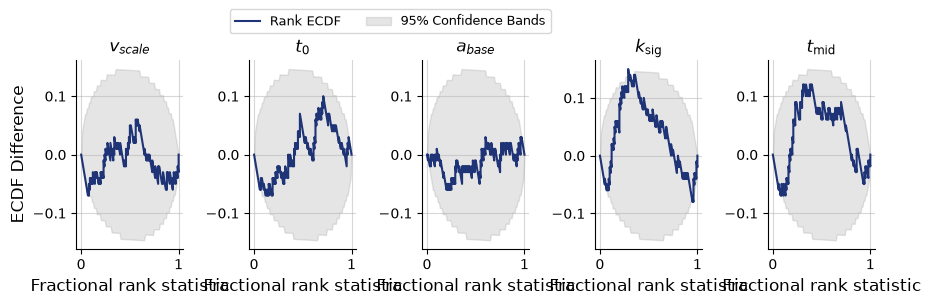

In [245]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_sims, figsize=(10, 3))
for ax in f3.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f3.axes[0].get_legend_handles_labels()
f3.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)
f3.savefig(f"images/diagnostics/calibration_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")

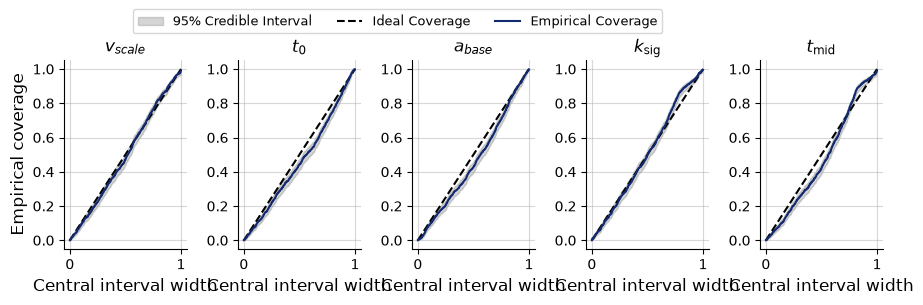

In [198]:
f4 = bf.diagnostics.coverage(samples, test_sims, figsize=(10, 3))
for ax in f4.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f4.axes[0].get_legend_handles_labels()
f4.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)
f4.savefig(f"images/diagnostics/coverage_{MODEL_NAMES[0]}.pdf", bbox_inches="tight")


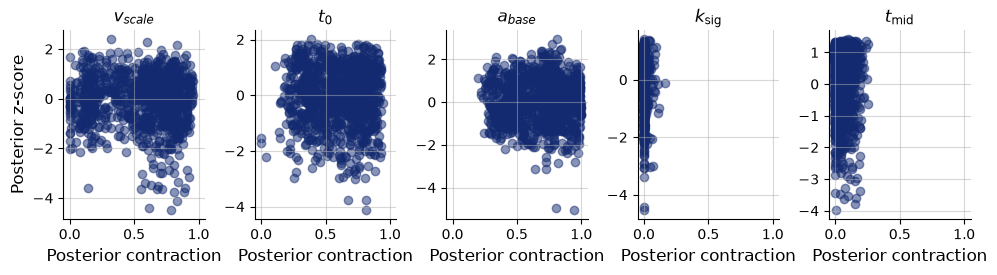

In [199]:
f5 = bf.diagnostics.z_score_contraction(samples, test_sims, figsize=(10, 3))

for ax in f5.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)
f5.savefig(f"images/diagnostics/z_score_contraction_{boundary_function}.pdf", bbox_inches="tight")


## **Inference**

In [96]:
empirical_data = pd.read_csv("./data/Katsimposis/experiment-2-Flash.csv")

# mapping
mapping_diff = {
    "[0.55, 0.45]": 0.1,
    "[0.6, 0.4]": 0.2,
    "[0.65, 0.35]": 0.3,
    "[0.7, 0.3]": 0.4,
    "[0.75,0.25]": 0.5,
    "[0.8,0.2]": 0.6
}
empirical_data['difficulty'] = empirical_data["difficulty"].replace(mapping_diff)

mapping_deadline = {
    "Deadline": 1,
    "No Deadline": 0
}
empirical_data["has_deadline"] = empirical_data["deadline"].replace(mapping_deadline)
empirical_data["deadline"] = empirical_data["deadline"].replace(mapping_deadline)

mapping_cue = {
    "AC":1,
    "SP":0
}
empirical_data["cue"] = empirical_data["cue"].replace(mapping_cue)


empirical_data = empirical_data[
    (empirical_data["cue"] == CUE) & (empirical_data["deadline"] == HAS_DEADLINE)
].reset_index(drop=True)
# print(empirical_data.shape, empirical_data["difficulty"].unique())

In [99]:
results = {}  # pp -> posterior samples

for pp_id, group in empirical_data.groupby("pp"):
    rt = group["rt"].to_numpy(dtype=np.float64)
    choice = group["acc"].to_numpy(dtype=np.float64)
    coherence = group["difficulty"].to_numpy(dtype=np.float64)
    cue = group["cue"].to_numpy(dtype=np.float64)
    deadline = group["has_deadline"].to_numpy(dtype=np.float64)

    if len(rt) < 10:
        continue

    data = {
        "rt": rt[np.newaxis, :],
        "choice": choice[np.newaxis, :],
        "coherence": coherence[np.newaxis, :],
        "cue": cue[np.newaxis, :],
        "has_deadline": deadline[np.newaxis, :],
    }

    # volle Posterior-Samples behalten, NICHT mitteln
    samples = approximator.sample(num_samples=1000, conditions=data)
    results[pp_id] = {
        "posterior": samples,   # für PPC-Simulation weiterverwenden
        "n_trials": len(rt),
        "empirical_rt": rt,
        "empirical_choice": choice,
        "coherence": coherence,
    }

Sampling: 100%|██████████| 1/1 [00:00<00:00, 10.72batch/s]


In [100]:
def samples_dict_to_array(samples, param_order=("v_scale", "t0", "a_base", "lam")):
    """Convert BayesFlow's samples dict into the (n_draws, n_params) array
    that resimulate_from_posterior expects."""
    return np.stack([np.asarray(samples[p]).reshape(-1) for p in param_order], axis=1)

In [101]:
def _plot_rt_distribution(ax, empirical_df, posterior_draws, model="exponential",
                           n_resim=100, seed=None, pp_label=""):
    """Draws empirical vs. simulated RT distribution (correct/error) into a given ax."""
    sims = resimulate_from_posterior(posterior_draws, model=model,
                                      n_resim=n_resim, seed=seed)

    rt_c_emp = empirical_df.loc[empirical_df["acc"] == 1, "rt"]
    rt_e_emp = empirical_df.loc[empirical_df["acc"] == 0, "rt"]
    ax.hist(rt_c_emp, bins=40, density=True, alpha=0.35, color="tab:blue", label="emp. correct")
    ax.hist(rt_e_emp, bins=40, density=True, alpha=0.35, color="tab:red", label="emp. error")

    sim_rt_c = np.concatenate([s["rt"][s["choice"] == 1] for s in sims])
    sim_rt_e = np.concatenate([s["rt"][s["choice"] == 0] for s in sims])
    ax.hist(sim_rt_c, bins=40, density=True, histtype="step", lw=2,
            color="tab:blue", linestyle="--", label="sim. correct")
    ax.hist(sim_rt_e, bins=40, density=True, histtype="step", lw=2,
            color="tab:red", linestyle="--", label="sim. error")

    ax.set_xlabel("RT (s)")
    ax.set_ylabel("Density")
    ax.set_title(pp_label)

In [102]:
def plot_rt_distributions_grid(empirical_data, posterior_samples_per_pp,
                                model="exponential", n_resim=100, seed=None,
                                n_cols=6, space_legend=1.06, space_figure=0.93):
    pp_ids = list(posterior_samples_per_pp.keys())
    n_pp = len(pp_ids)
    n_rows = int(np.ceil(n_pp / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows),
                              sharex=True, sharey=False)
    axes = np.atleast_2d(axes).reshape(n_rows, n_cols)

    for i, pp_id in enumerate(pp_ids):
        ax = axes[i // n_cols, i % n_cols]
        emp = empirical_data[empirical_data["pp"] == pp_id]
        draws = samples_dict_to_array(posterior_samples_per_pp[pp_id])
        _plot_rt_distribution(ax, emp, draws, model=model, n_resim=n_resim,
                               seed=seed, pp_label=f"Participant {pp_id}")

    # leere Subplots ausblenden, falls n_pp nicht exakt n_rows*n_cols füllt
    for j in range(n_pp, n_rows * n_cols):
        axes[j // n_cols, j % n_cols].axis("off")

    # eine gemeinsame Legende statt 24x dieselbe
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=12,
            bbox_to_anchor=(0.5, space_legend))  # statt 1.02 – weiter weg vom Grid

    plt.tight_layout(rect=[0, 0, 1, space_figure])  # oberen 7% für Legende+Titel reservieren
    return fig

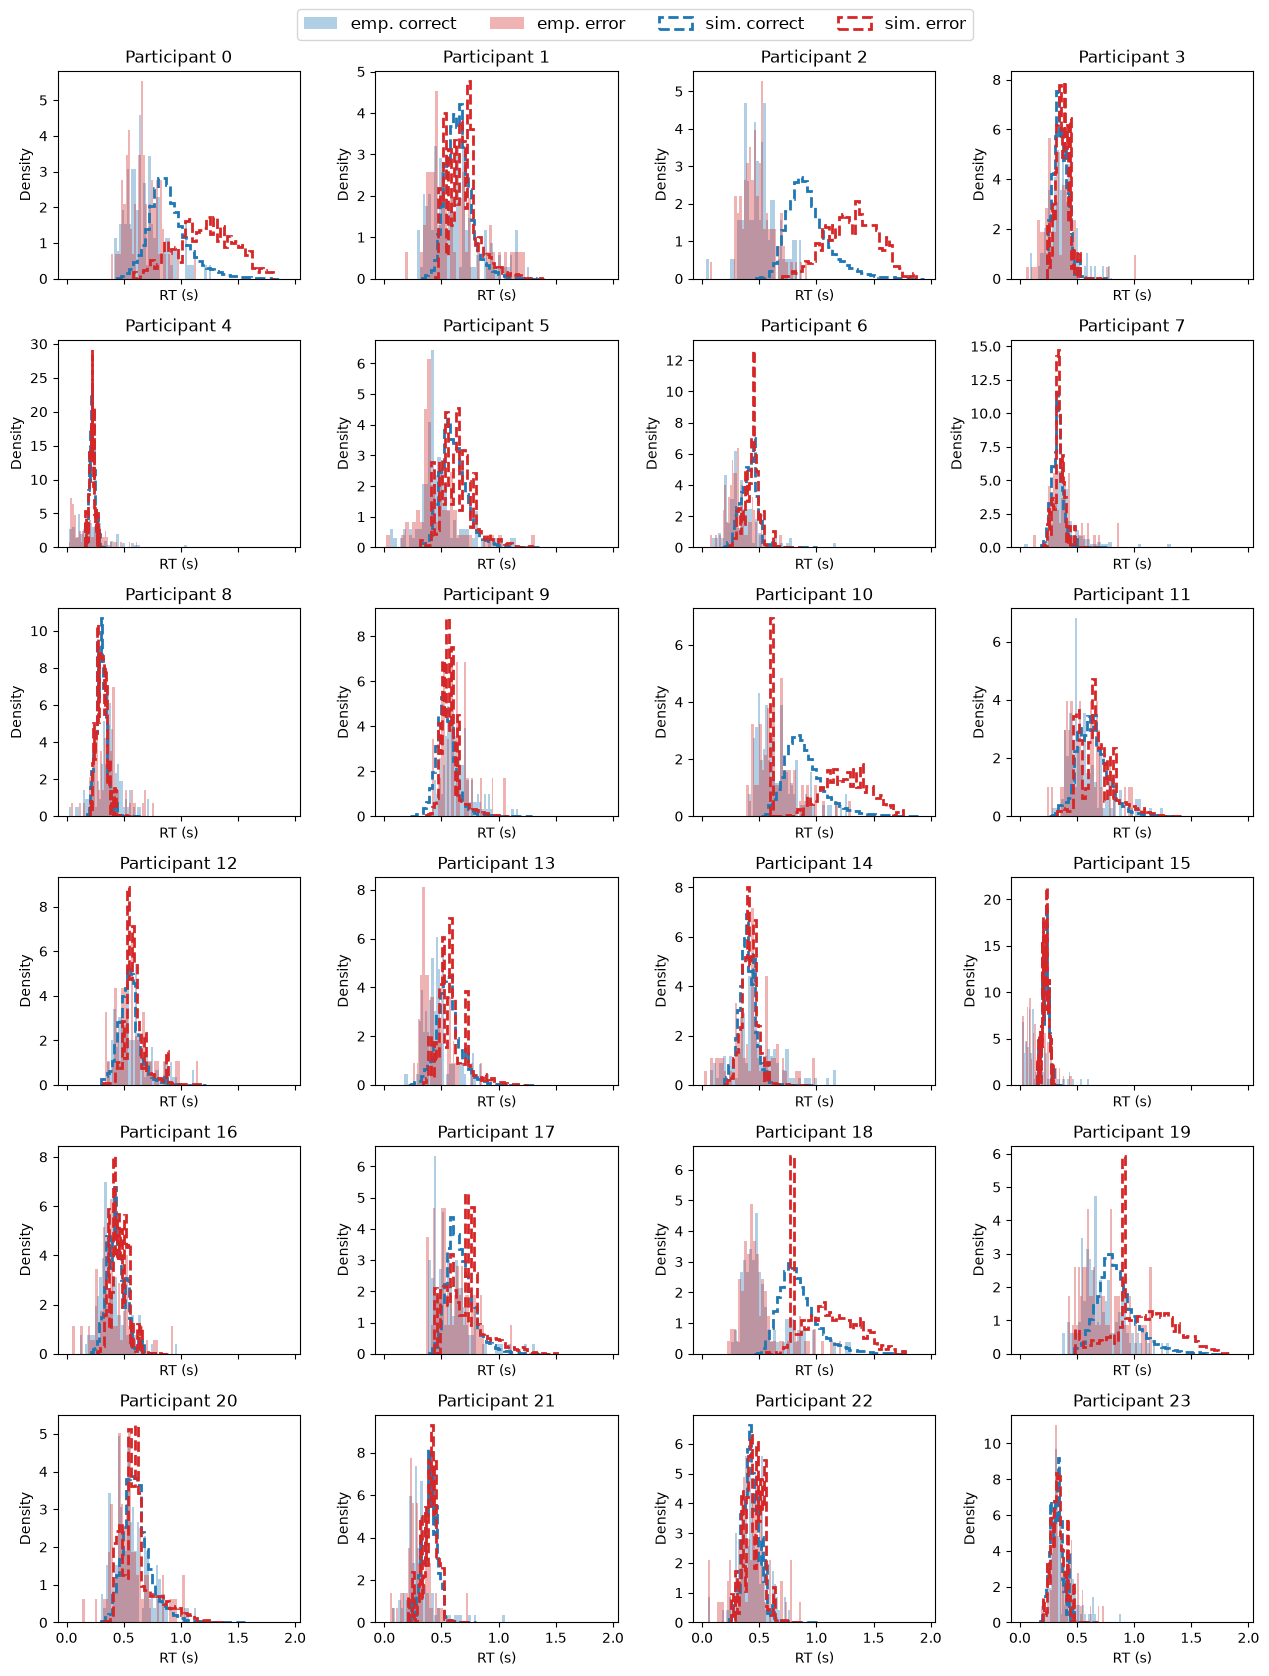

In [ ]:
fig = plot_rt_distributions_grid(empirical_data, {pp_id: res["posterior"] for pp_id, res in results.items()}, 
n_cols = 4, space_legend = 1, space_figure = 0.98)
plt.show()
fig.savefig(f"images/ppc_{MODEL_NAMES[0]}_all.pdf", bbox_inches="tight")

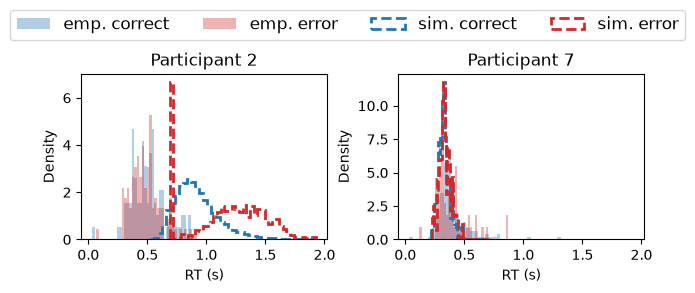

In [ ]:
selected = {2: results[2]["posterior"], 7: results[7]["posterior"]}

fig = plot_rt_distributions_grid(empirical_data, selected, n_cols=2)
plt.show()
fig.savefig(f"images/ppc_{MODEL_NAMES[0]}_participant_2_7.pdf", bbox_inches="tight")

In [105]:
def plot_ppc_aggregated(empirical_data, posterior_samples_per_pp, model="exponential",
                         n_resim=50, seed=None):
    """
    posterior_samples_per_pp : dict {pp_id: samples_dict_from_approximator}
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ax_acc, ax_qpp = axes

    for pp_id, samples in posterior_samples_per_pp.items():
        emp = empirical_data[empirical_data["pp"] == pp_id]
        draws = samples_dict_to_array(samples)
        sims = resimulate_from_posterior(draws, model=model, n_resim=n_resim, seed=seed)

        # accuracy lines, low alpha, one per participant
        emp_acc = emp.groupby("coherence")["acc"].mean()
        ax_acc.plot(emp_acc.index, emp_acc.values, "-", color="black", alpha=0.15)

        sim_accs = pd.concat([
            pd.DataFrame({"coherence": s["coherence"], "choice": s["choice"]})
              .query("choice != -1").groupby("coherence")["choice"].mean()
            for s in sims
        ], axis=1).median(axis=1)
        ax_acc.plot(sim_accs.index, sim_accs.values, "--", color="tab:orange", alpha=0.15)

        # QPP points, low alpha, pooled
        ec, ee = _qpp_points(emp)
        for p, qs in ec: ax_qpp.plot([p]*len(qs), qs, "o", color="tab:blue", alpha=0.15)
        for p, qs in ee: ax_qpp.plot([p]*len(qs), qs, "o", color="tab:red", alpha=0.15)

    ax_acc.set_xlabel("coherence"); ax_acc.set_ylabel("P(correct)")
    ax_acc.set_title("Accuracy by difficulty (black=emp, orange=sim), all pp")
    ax_qpp.set_xlabel("P(correct)"); ax_qpp.set_ylabel("RT quantiles (s)")
    ax_qpp.set_title("Quantile-probability, all pp (empirical only shown)")

    plt.tight_layout()
    return fig

In [106]:
for pp_id, res in results.items():
    emp = empirical_data[empirical_data["pp"] == pp_id]
    draws = samples_dict_to_array(res["posterior"])
    fig = plot_ppc_participant(emp, draws, pp_label=f"(pp {pp_id})")
    plt.show()

NameError: name 'plot_ppc_participant' is not defined

In [ ]:
resim_datasets = resimulate_from_posterior(all_samples, model="exponential", n_resim=100)

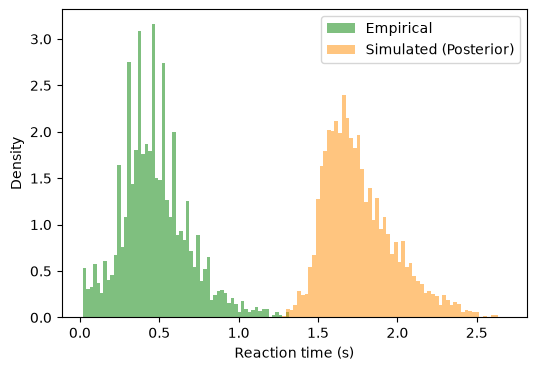

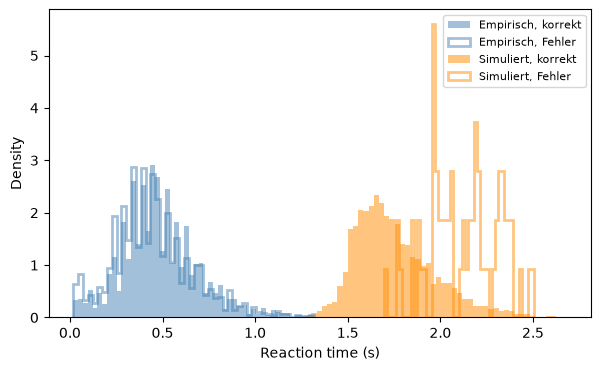

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [ ]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())

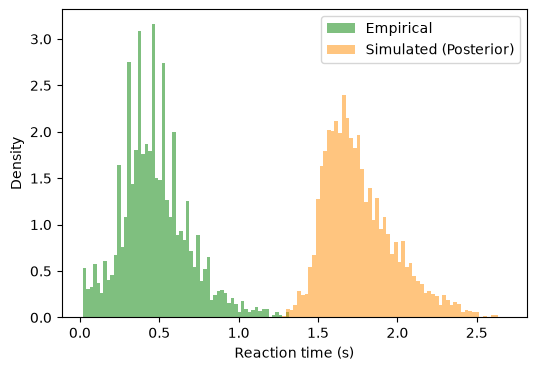

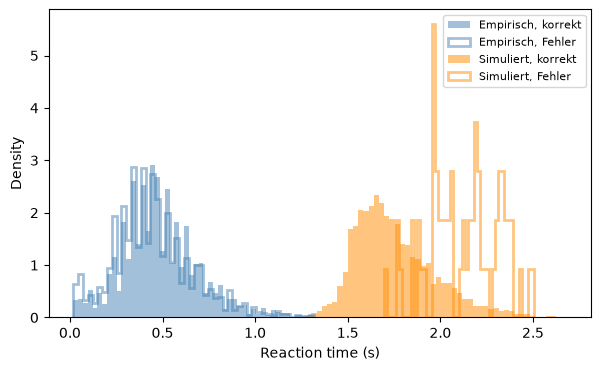

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [ ]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())